# Roll-for-Sandwich ratings — EDA

The ["Roll for Sandwich"](https://docs.google.com/spreadsheets/d/11fjXIUbUae35AFNlp-f10t3hSjbq5tiBykLA_IbUojs) project rolls
dice to pick a sandwich's bread, main, cheese, roughage, wild magic, and sauce, then rates the result 0-10.
This reframes the imbalance question as a **skewed regression** (plan.md 3.3): ratings pile up high (~50% above 7)
while low scores are rare (~11% below 3), so the "negative" examples are the low-rated sandwiches.

This notebook reproduces the reference EDA (rating distribution, ratings over time, per-ingredient rating spreads),
trains an XGBoost regressor on the multi-hot ingredient encoding, checks it on near-identical **matched pairs**, and
runs the **deli-counter** search for the best and worst sandwich the model can build. The plotting helpers live in
`negative_ml.viz.sandwiches`, so this notebook and `scripts/sandwiches_eda_model.py` draw the same figures.

In [1]:
from itertools import product

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_curve

from negative_ml.core import eval as ev
from negative_ml.core.experiment import positive_scores
from negative_ml.core.mmp import find_matched_pairs, mmp_metrics, score_pairs
from negative_ml.core.splitting import random_split
from negative_ml.models import feature_selected_ridge_classifier
from negative_ml.sandwich import io as sandwiches
from negative_ml.sandwich import viz
from negative_ml.sandwich.config import (
    SANDWICH_CLF_TOP_FEATURES,
    SANDWICH_FREQ_THRESHOLD_VIOLIN,
    SANDWICH_GOOD_RATING_THRESHOLD,
    SANDWICH_RIDGE_ALPHA,
)
from negative_ml.viz.style import dark2

ds = sandwiches.load()
frame = sandwiches.clean_ratings(sandwiches.read_ratings())
n_good = int((ds.y >= SANDWICH_GOOD_RATING_THRESHOLD).sum())
print(
    f"{ds.n_samples} sandwiches; mean rating {ds.y.mean():.2f}; "
    f"{n_good} rated >= {SANDWICH_GOOD_RATING_THRESHOLD:g} (the rare good minority)"
)
frame.head()

239 sandwiches; mean rating 6.69; 52 rated >= 9 (the rare good minority)


,Bread,Main,Cheese,Roughage,Wild Magic,Sauce,Rating,Season,Episode,Clean_Rating
0,Seeded,Pastrami,-,Pickles,Salt and pepper,Yellow mustard,6.0/10,S1,1,6.0
1,Seeded,Tuna,No cheese,"Lettuce, avocado",Extra roughage,Mayonnaise,5.0/10,S1,2,5.0
2,Seeded,Crab salad,Mexican style,Tomato,-,Ketchup,2.0/10,S1,3,2.0
3,Seeded,"Tuna, chicken",No cheese,Apple,Extra main,Peanut butter,5.5/10,S1,4,5.5
4,Seeded,"Turkey, chicken",Sharp cheddar,White onion,-,Yellow mustard,7.0/10,S1,5,7.0


## 1. Rating distribution

Ratings are skewed high with a thin low tail — exactly the imbalance the study turns on, now in a regression setting.

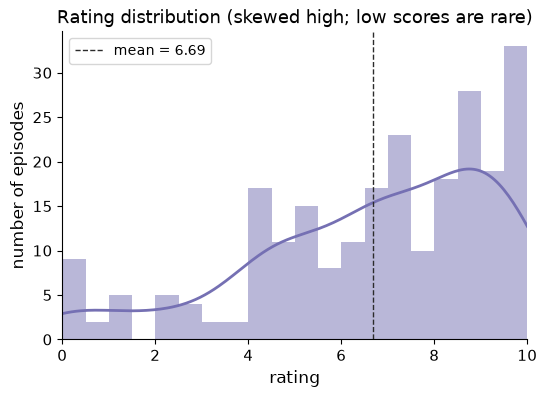

In [2]:
fig, ax = plt.subplots(figsize=(6, 4))
viz.plot_rating_distribution(ds.y, ax)
plt.show()

## 2. Ratings over time

Rating versus episode number across the show's run (non-numeric episode markers are dropped).

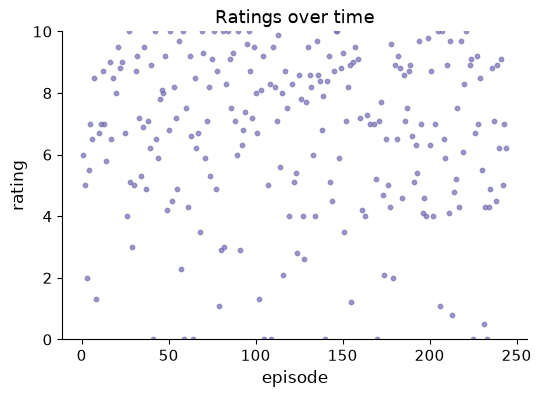

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
viz.plot_rating_timeline(ds.meta["Episode"], ds.y, ax)
plt.show()

## 3. Which ingredient values are well sampled?

The combinatorial menu is sparsely explored, so most ingredient values appear once or twice. The EDA and the deli
search restrict to values seen at least a handful of times (`SANDWICH_FREQ_THRESHOLD_VIOLIN`).

In [4]:
frequent = sandwiches.ingredient_value_counts(frame, SANDWICH_FREQ_THRESHOLD_VIOLIN)
{col: len(values) for col, values in frequent.items()}

{'Bread': 14,
 'Main': 10,
 'Cheese': 10,
 'Roughage': 1,
 'Wild Magic': 6,
 'Sauce': 4}

## 4. Rating by ingredient (violin + swarm)

How the rating distribution shifts with each ingredient choice, restricted to the well-sampled values. A violin shows
the spread; the jittered points are the individual sandwiches.

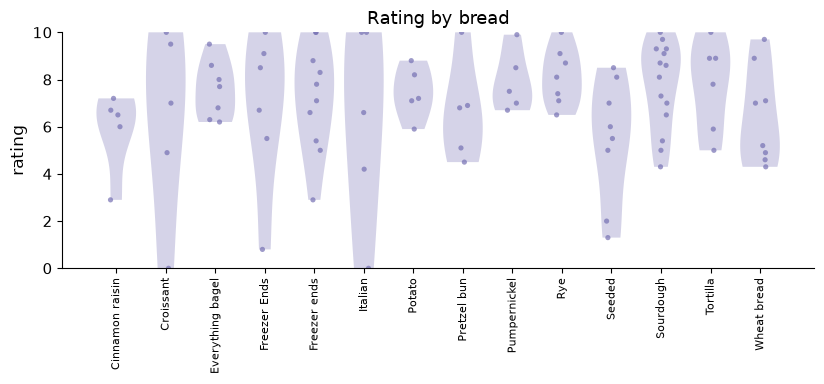

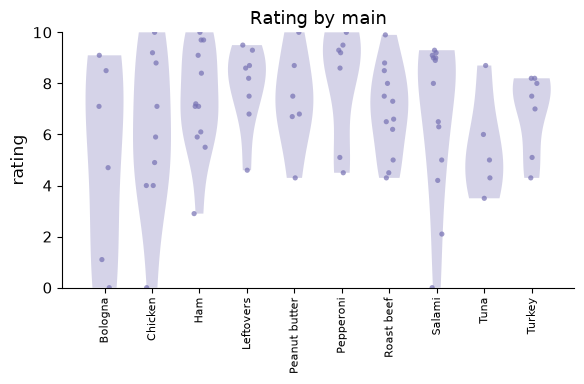

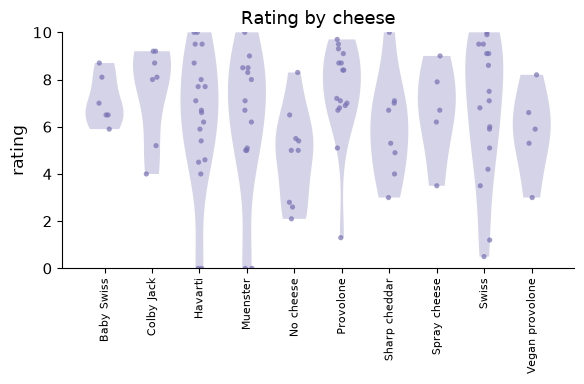

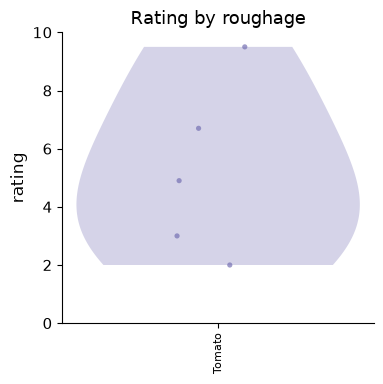

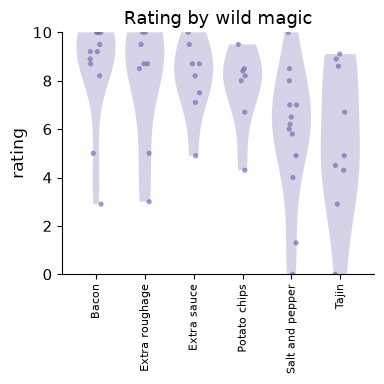

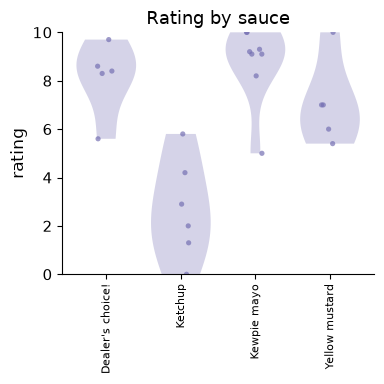

In [5]:
for col in sandwiches.INGREDIENT_COLS:
    values = frequent[col]
    if not values:
        continue
    sub = frame[frame[col].isin(values)]
    fig, ax = plt.subplots(figsize=(max(4, 0.6 * len(values)), 4))
    viz.plot_ingredient_violin(
        sub[col].to_numpy(), sub["Clean_Rating"].to_numpy(), ax, col
    )
    plt.tight_layout()
    plt.show()

## 5. Multi-hot encoding + an XGBoost rating regressor

Each ingredient value becomes its own indicator column, so a sandwich is a multi-hot row with six ones. We fit the
house XGBoost regressor on a random split — with small, shallow `SANDWICH_XGB_PARAMS`, since a few hundred sandwiches
and hundreds of one-hot columns would overfit the baseball-scale defaults. This is a genuinely hard, sparse problem,
so the held-out correlation is modest.

{'auroc': 0.561, 'auprc': 0.263, 'f1': 0.333, 'precision_at_k': 0.208, 'enrichment_factor': 1.0}


/Users/jackie16201/micromamba/envs/negative_ml/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [  9  12  14  15  19  33  34  39  40  49  56  68  91  99 102 103 104 119
 130 135 137 141 142 149 150 153 155 172 176 177 178 181 195 199 209 213
 219 220 223 226 230 234 241 244 247 248 266 286 289 295 296 298 308 321
 331 335 351 358 359 360 362 369 370 372 373 380 381 387 389 397 402 413
 422 423 428 431 432 433 448 453 456 467 475 479 486 498 501 503 506 510
 512 513 516 522 540 549 550 569 573 593 594 596 598 601 604 608 610 613
 617 624 627 628 634 642 649 660 662 678 681 682 689 697 701 703 723 738
 742 746 750 752 753 754 755 760 768 811 819 823 828 830 837 842] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/Users/jackie16201/micromamba/envs/negative_ml/lib/python3.14/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered

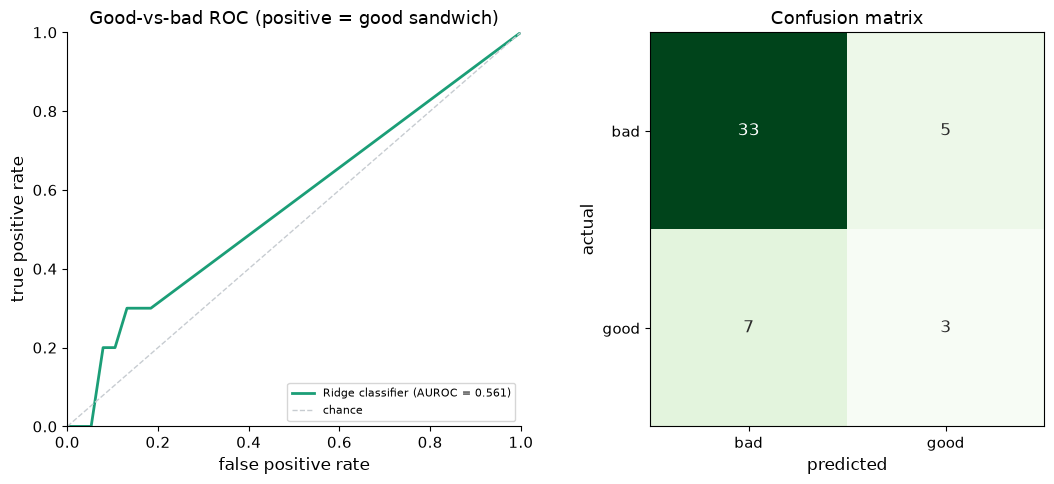

In [6]:
# The domain moved from a 0-10 rating regressor to a good-vs-bad classifier
# (SANDWICH_GOOD_RATING_THRESHOLD), matching modeling.py / downselection.py, so
# this quick demo trains the same feature-selected ridge classifier they use.
cds = sandwiches.to_classification(ds)
train_idx, test_idx = random_split(cds)
model = feature_selected_ridge_classifier(
    k=SANDWICH_CLF_TOP_FEATURES, alpha=SANDWICH_RIDGE_ALPHA
)
model.fit(cds.X[train_idx], cds.y[train_idx])

y_test = cds.y[test_idx]
# RidgeClassifier exposes decision_function, not predict_proba; positive_scores
# handles that (see negative_ml.core.experiment).
y_score = positive_scores(model, cds.X[test_idx])
y_pred = model.predict(cds.X[test_idx])
print({k: round(v, 3) for k, v in ev.compute_metrics(y_test, y_score).items()})

fpr, tpr, _ = roc_curve(y_test, y_score)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
viz.plot_roc_curves(
    [("Ridge classifier", fpr, tpr, ev.auroc(y_test, y_score))], axes[0]
)
matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])
viz.plot_confusion(matrix, axes[1])
plt.tight_layout()
plt.show()

## 6. Matched pairs: near-identical sandwiches

Matched pairs are sandwiches that differ in only one or a few ingredients — near-twins whose ratings can still
diverge. Matched-pair accuracy asks whether a model fit on all the data ranks the higher-rated twin above its pair,
probing fine-grained discrimination rather than broad class separation. The menu is sparse, so the closest real pairs
differ in three of six ingredients.

In [7]:
# Matched-pair evaluation now lives in negative_ml.core.mmp (shared across all
# three domains — see scripts/mmp_experiments.py); reuse it here directly on the
# classifier trained above instead of the retired sandwiches.matched_pairs helper.
pairs = find_matched_pairs(cds.X, cds.y, max_pairs=200)
scored = score_pairs(model, cds.X, pairs)
metrics = mmp_metrics(scored)
print(
    f"matched-pair concordance = {metrics['concordance']:.3f} over {len(pairs)} pairs"
)

for _, row in scored.head(5).iterrows():
    i, j = int(row["idx_pos"]), int(row["idx_neg"])
    good = " / ".join(cds.meta.iloc[i][sandwiches.INGREDIENT_COLS])
    bad = " / ".join(cds.meta.iloc[j][sandwiches.INGREDIENT_COLS])
    print(f"  good (score={row['score_pos']:.2f}): {good}")
    print(f"  bad  (score={row['score_neg']:.2f}): {bad}\n")

matched-pair concordance = 0.500 over 4 pairs
  good (score=0.32): Pumpernickel / Roast beef / Swiss / Cucumber, tomato / Sichuan peppercorn / Barbecue sauce
  bad  (score=0.32): Cinnamon raisin / Tuna / Swiss / Lettuce / Sichuan peppercorn / Brown mustard

  good (score=0.51): Italian / Ham / Havarti / Cucumber / Bacon / Fruit jelly / jam
  bad  (score=0.32): Seeded / Bologna / Muenster / Cucumber / Extra roughage / Jelly / jam

  good (score=0.32): Gluten free white / Buffalo burger / Provolone / Tomato / Potato chips / Ponzu
  bad  (score=0.32): Pumpernickel / Peanut butter / Provolone / Tomato / Potato chips / Peanut butter

  good (score=0.53): Waffle / Pepperoni / Grated parmesan x3 / Pickled onions, olives / Grill it! / MayoChup
  bad  (score=0.32): Waffle / Ham / Provolone / Banana / Potato chips / Dealer's choice!



## 7. Deli counter: the best and worst sandwich

Enumerate every sandwich the model can build from the popular ingredients and ask it for the highest- and
lowest-scoring one (predictions clipped to the 0-10 scale). The reference notebook scored these one row at a time;
here the whole candidate menu is predicted in a single batch.

searched 33,600 sandwiches
best  score=0.80: Sourdough / Salami / Havarti / Tomato / Bacon / Kewpie mayo
worst score=0.32: Sourdough / Roast beef / Havarti / Tomato / Salt and pepper / Ketchup


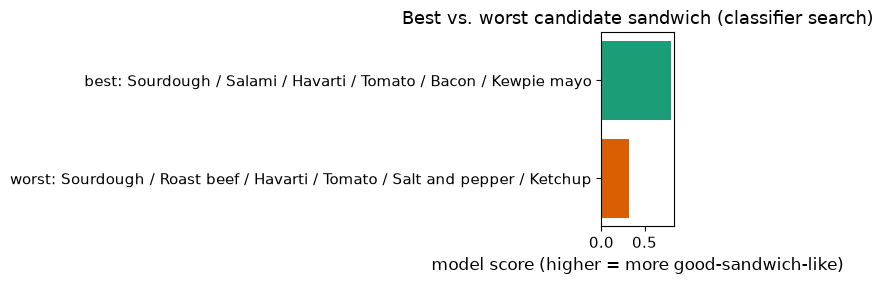

In [8]:
# plot_best_worst_sandwich was retired along with the regressor; draw the two
# bars directly instead (scores are the classifier's positive_scores, not
# calibrated probabilities).
value_lists = [frequent[col] for col in sandwiches.INGREDIENT_COLS]
candidates = pd.DataFrame(
    list(product(*value_lists)), columns=sandwiches.INGREDIENT_COLS
)
X_cand, _ = sandwiches.encode_ingredients(candidates, feature_names=cds.feature_names)
scores = positive_scores(model, X_cand)

best, worst = int(scores.argmax()), int(scores.argmin())
best_label = " / ".join(candidates.iloc[best])
worst_label = " / ".join(candidates.iloc[worst])
print(f"searched {len(candidates):,} sandwiches")
print(f"best  score={scores[best]:.2f}: {best_label}")
print(f"worst score={scores[worst]:.2f}: {worst_label}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(
    [f"worst: {worst_label}", f"best: {best_label}"],
    [scores[worst], scores[best]],
    color=[dark2(1), dark2(0)],
)
ax.set_xlabel("model score (higher = more good-sandwich-like)")
ax.set_title("Best vs. worst candidate sandwich (classifier search)")
plt.tight_layout()
plt.show()